In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Configuración de estilo
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

In [2]:
# ============================================================
# 1. Generación de datos (mezcla de dos normales -> bimodal)
# ============================================================
np.random.seed(2026)
n = 500
# Mezcla: 60% N(-2, 1) y 40% N(3, 1)
datos = np.concatenate([
    np.random.normal(-2, 1, int(0.6*n)),
    np.random.normal(3, 1, int(0.4*n))
])
np.random.shuffle(datos)

In [3]:
# ============================================================
# 2. Definición de funciones núcleo
# ============================================================
def K_uniforme(u):
    """Núcleo uniforme: 1/2 si |u| <= 1, 0 en otro caso."""
    return np.where(np.abs(u) <= 1, 0.5, 0.0)

def K_gaussiano(u):
    """Núcleo gaussiano estándar."""
    return np.exp(-0.5 * u**2) / np.sqrt(2 * np.pi)

# ============================================================
# 3. Implementación del KDE
# ============================================================
def kde_estimator(x_eval, datos, h, kernel_func):
    """
    Calcula el estimador KDE para un conjunto de puntos x_eval.

    Parámetros
    ----------
    x_eval : array_like
        Puntos donde evaluar la densidad.
    datos : array_like
        Muestra de datos.
    h : float
        Ancho de banda.
    kernel_func : callable
        Función núcleo K(u).

    Retorna
    -------
    f_hat : array_like
        Estimación de la densidad en x_eval.
    """
    n = len(datos)
    # Vectorización: (n_datos, n_eval)
    u = (x_eval[None, :] - datos[:, None]) / h
    f_hat = np.mean(kernel_func(u), axis=0) / h
    return f_hat

In [4]:
# ============================================================
# 4. Ancho de banda por la regla de Silverman
# ============================================================
sigma_hat = np.std(datos, ddof=1)
h_silverman = 1.06 * sigma_hat / (n ** 0.2)  # n^0.2 = n^(1/5)

print("=" * 60)
print("Estimación de Densidad por Núcleos (KDE)")
print("=" * 60)
print(f"Tamaño de muestra n        : {n}")
print(f"Desviación estándar muestral: {sigma_hat:.4f}")
print(f"Ancho de banda (Silverman) : {h_silverman:.4f}")
print("=" * 60)

Estimación de Densidad por Núcleos (KDE)
Tamaño de muestra n        : 500
Desviación estándar muestral: 2.6419
Ancho de banda (Silverman) : 0.8080


In [5]:
# ============================================================
# 5. Evaluación del KDE en una malla de puntos
# ============================================================
x_vals = np.linspace(datos.min() - 1, datos.max() + 1, 500)

# KDE con núcleo Uniforme
f_unif = kde_estimator(x_vals, datos, h_silverman, K_uniforme)

# KDE con núcleo Gaussiano
f_gauss = kde_estimator(x_vals, datos, h_silverman, K_gaussiano)

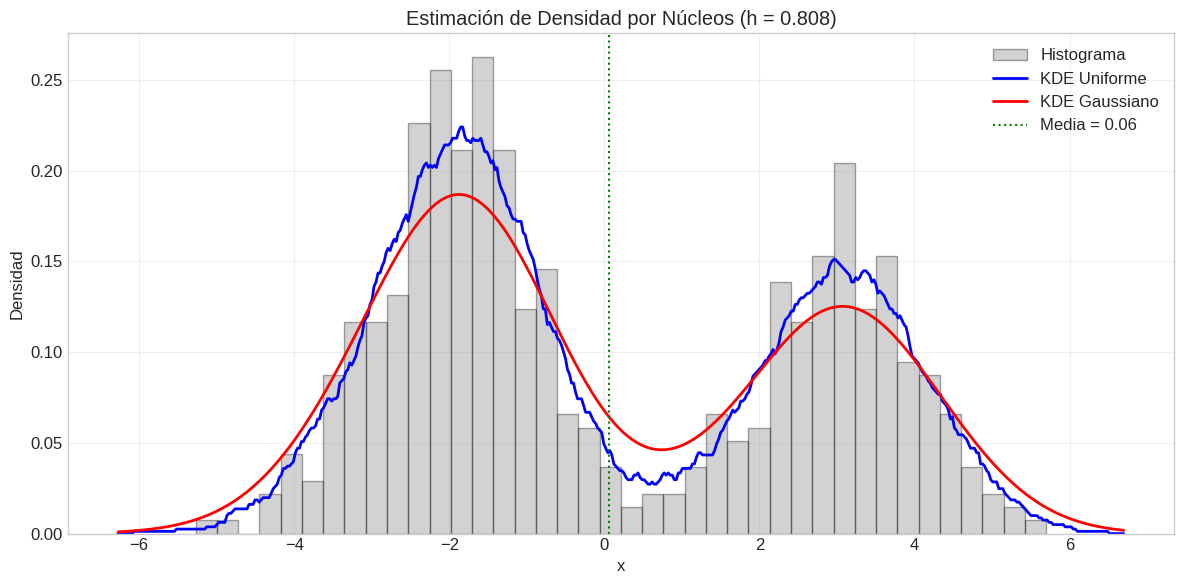

In [6]:
# ============================================================
# 6. Gráfica comparativa de KDE con diferentes núcleos
# ============================================================
plt.figure(figsize=(12, 6))
plt.hist(datos, bins=40, density=True, alpha=0.35, color='gray',
         edgecolor='black', label='Histograma')
plt.plot(x_vals, f_unif, 'b-', lw=2, label='KDE Uniforme')
plt.plot(x_vals, f_gauss, 'r-', lw=2, label='KDE Gaussiano')
plt.axvline(x=datos.mean(), color='green', linestyle=':', lw=1.5,
            label=f'Media = {datos.mean():.2f}')
plt.xlabel('x')
plt.ylabel('Densidad')
plt.title(f'Estimación de Densidad por Núcleos (h = {h_silverman:.3f})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

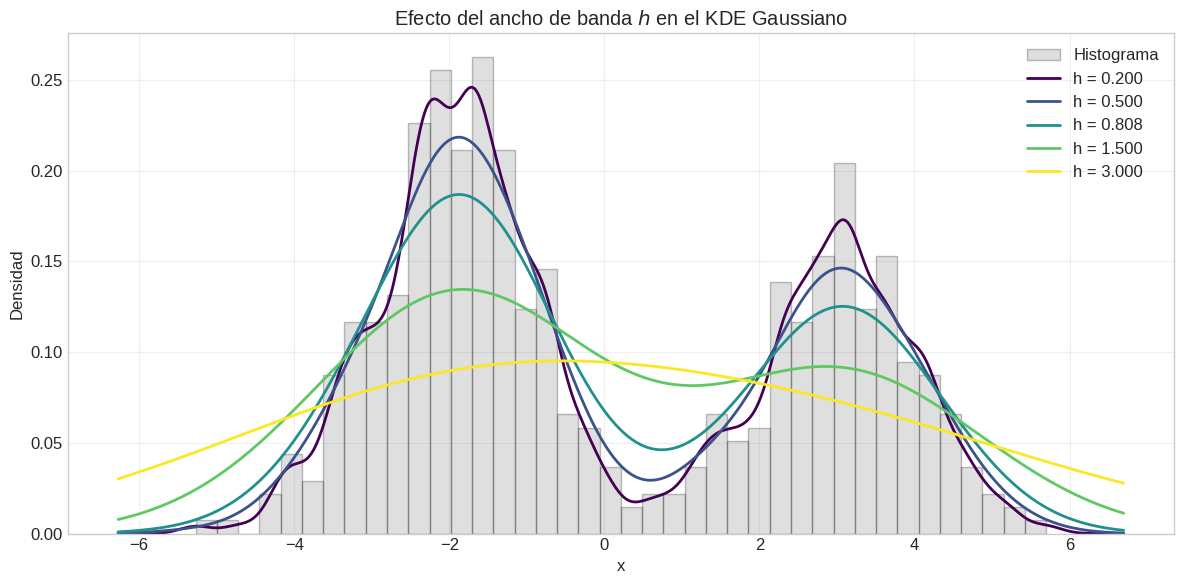

In [7]:
# ============================================================
# 7. Efecto del ancho de banda h
# ============================================================
h_vals = [0.2, 0.5, h_silverman, 1.5, 3.0]
colores = plt.cm.viridis(np.linspace(0, 1, len(h_vals)))

plt.figure(figsize=(12, 6))
plt.hist(datos, bins=40, density=True, alpha=0.25, color='gray',
         edgecolor='black', label='Histograma')

for h_val, color in zip(h_vals, colores):
    f_h = kde_estimator(x_vals, datos, h_val, K_gaussiano)
    plt.plot(x_vals, f_h, color=color, lw=2,
             label=f'h = {h_val:.3f}')

plt.xlabel('x')
plt.ylabel('Densidad')
plt.title('Efecto del ancho de banda $h$ en el KDE Gaussiano')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Comparación con scipy.stats.gaussian_kde:
Ancho de banda usado por scipy: 0.8074
Diferencia media con KDE manual: 0.000021


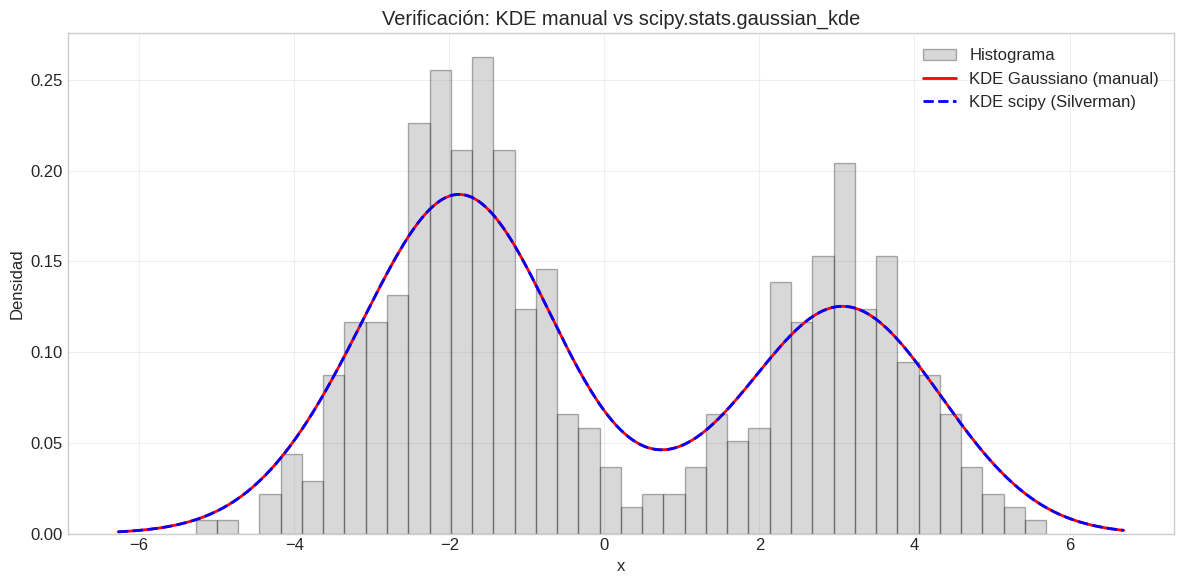


Verificación de la derivación (h = 0.50):
Diferencia media entre F_e derivada y KDE Uniforme: 0.00000000


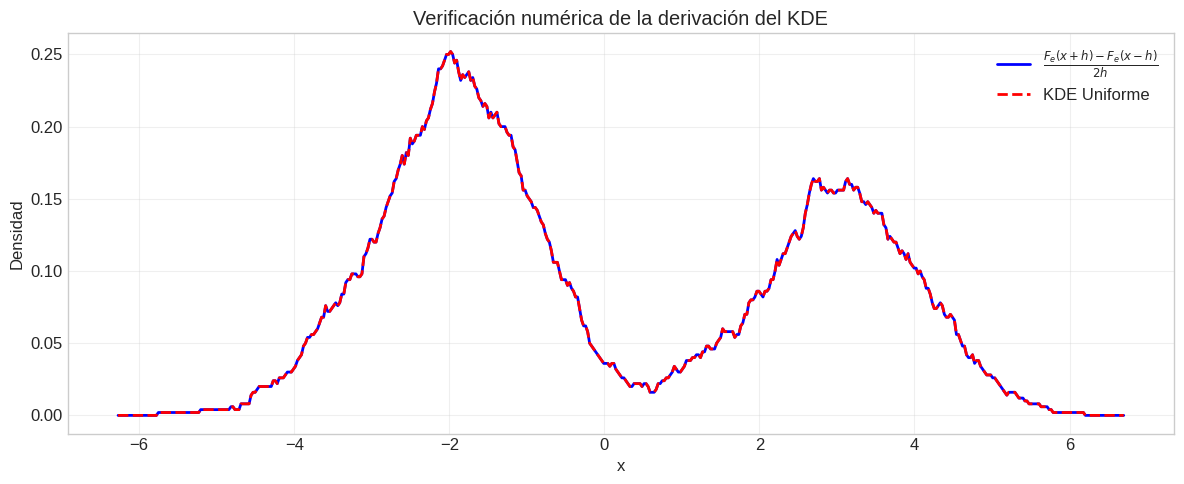

In [8]:
# ============================================================
# 8. Comparación con KDE de scipy (usando gaussian_kde)
# ============================================================
kde_scipy = stats.gaussian_kde(datos, bw_method='silverman')
f_scipy = kde_scipy(x_vals)

print("\nComparación con scipy.stats.gaussian_kde:")
print(f"Ancho de banda usado por scipy: {kde_scipy.factor * sigma_hat:.4f}")
print(f"Diferencia media con KDE manual: {np.mean(np.abs(f_gauss - f_scipy)):.6f}")

plt.figure(figsize=(12, 6))
plt.hist(datos, bins=40, density=True, alpha=0.3, color='gray',
         edgecolor='black', label='Histograma')
plt.plot(x_vals, f_gauss, 'r-', lw=2, label='KDE Gaussiano (manual)')
plt.plot(x_vals, f_scipy, 'b--', lw=2, label='KDE scipy (Silverman)')
plt.xlabel('x')
plt.ylabel('Densidad')
plt.title('Verificación: KDE manual vs scipy.stats.gaussian_kde')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 9. Verificación de la derivación: KDE Uniforme como
#    diferencia de funciones de distribución empíricas
# ============================================================
def F_empirica(x, datos):
    """Función de distribución empírica."""
    return np.mean(datos[:, None] <= x[None, :], axis=0)

h_test = 0.5
x_test = np.linspace(datos.min() - 1, datos.max() + 1, 500)

# Aproximación por diferencias centrales de la F_e
f_derivada = (F_empirica(x_test + h_test, datos) -
              F_empirica(x_test - h_test, datos)) / (2 * h_test)

# KDE con núcleo uniforme
f_kde_unif = kde_estimator(x_test, datos, h_test, K_uniforme)

print("\nVerificación de la derivación (h = {:.2f}):".format(h_test))
print(f"Diferencia media entre F_e derivada y KDE Uniforme: "
      f"{np.mean(np.abs(f_derivada - f_kde_unif)):.8f}")

plt.figure(figsize=(12, 5))
plt.plot(x_test, f_derivada, 'b-', lw=2, label=r'$\frac{F_e(x+h) - F_e(x-h)}{2h}$')
plt.plot(x_test, f_kde_unif, 'r--', lw=2, label=r'KDE Uniforme')
plt.xlabel('x')
plt.ylabel('Densidad')
plt.title('Verificación numérica de la derivación del KDE')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()